# 06 — Análise Transversal

## Objetivo

Realizar uma **fotografia analítica de um único ano** da camada `Consumo`, comparando municípios do estado selecionado segundo participação, desempenho e características dos grupos.

### Regra metodológica central

A estrutura de desempenho depende do ano selecionado:

| Período | Disciplinas analisadas |
|---|---|
| 1998–2008 | `OBJETIVA` e `REDACAO_ANTIGA` |
| 2009–2025 | `CN`, `CH`, `LC`, `MT` e `REDACAO_NOVA` |

**Não se comparam as versões antiga e nova da Redação como se fossem uma série homogênea.** Para um ano entre 1998 e 2008, a análise utiliza exclusivamente `OBJETIVA` e a Redação do período antigo. De 2009 a 2025, utiliza as quatro áreas e a Redação do período novo.

As mesmas regras são aplicadas às análises por escola, sexo e faixa etária. Nenhuma disciplina incompatível com o período é incluída nos gráficos ou resumos.


## 1. Configuração e carga

In [1]:
# ============================================================
# 1. CONFIGURAÇÃO E CARGA
# ============================================================
from _setup import *
import unicodedata
import warnings
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from enem_pipeline.config import (
    PROJECT_ROOT, DATA_DIR, METADATA_DIR, CONSUMO_DIR,
    UF_PROCESSAMENTO, ANO_INICIAL, ANO_FINAL
)
from utils.features_names import read_allfiles
from utils.eda import *
import time

warnings.filterwarnings("ignore", category=FutureWarning, module="seaborn")
pd.set_option("display.max_columns", None)
pd.set_option("display.width", 160)

# ============================================================
# PARÂMETROS DA ANÁLISE TRANSVERSAL
# ============================================================
ANO_TRANSVERSAL = 2009
UF_PROCESSAMENTO = "PA"

config_ano = configuracao_analise_transversal(ANO_TRANSVERSAL)
PERIODO_TRANSVERSAL = config_ano["periodo"]
PERIODO_ID_TRANSVERSAL = config_ano["periodo_id"]
DISCIPLINAS_TRANSVERSAL = config_ano["disciplinas"]
colunas_medias = config_ano["colunas_medias"]
nomes_disciplinas = config_ano["nomes_disciplinas"]
ORDEM_DISCIPLINAS = config_ano["ordem_disciplinas"]
colunas_top5 = nomes_disciplinas

out = read_allfiles(UF_PROCESSAMENTO)
painel = out["painel"]["data"]
faixa = out["faixa"]["data"]
grupo = out["grupo"]["data"]

print("=" * 80)
print("ANÁLISE TRANSVERSAL")
print("=" * 80)
print(f"Ano transversal: {ANO_TRANSVERSAL}")
print(f"UF: {UF_PROCESSAMENTO}")
print(f"Período metodológico: {PERIODO_TRANSVERSAL['rotulo']}")
print(f"Estrutura de desempenho: {PERIODO_TRANSVERSAL['estrutura']}")
print(f"Disciplinas incluídas: {', '.join(ORDEM_DISCIPLINAS)}")
print(f"Painel: {painel.shape[0]:,} linhas × {painel.shape[1]} colunas")
print(f"Faixa:  {faixa.shape[0]:,} linhas × {faixa.shape[1]} colunas")
print(f"Grupo:  {grupo.shape[0]:,} linhas × {grupo.shape[1]} colunas")



ANÁLISE TRANSVERSAL
Ano transversal: 2009
UF: PA
Período metodológico: 2009–2025
Estrutura de desempenho: AREAS
Disciplinas incluídas: REDACAO, CN, CH, LC, MT
Painel: 2,412 linhas × 82 colunas
Faixa:  35,600 linhas × 7 colunas
Grupo:  163,198 linhas × 16 colunas


## 2. Disponibilidade do ano transversal

In [2]:
# ============================================================
# 2. DISPONIBILIDADE DO ANO TRANSVERSAL
# ============================================================
anos_painel = set(pd.to_numeric(painel["ano"], errors="coerce").dropna().astype(int))
anos_faixa = set(pd.to_numeric(faixa["ano"], errors="coerce").dropna().astype(int))
anos_grupo = set(pd.to_numeric(grupo["ano"], errors="coerce").dropna().astype(int))

print(f"Ano selecionado: {ANO_TRANSVERSAL} — período {PERIODO_TRANSVERSAL['rotulo']}")
print(f"painel_municipal: {ANO_TRANSVERSAL in anos_painel}")
print(f"faixa_etaria_municipal: {ANO_TRANSVERSAL in anos_faixa}")
print(f"desempenho_grupos_municipal: {ANO_TRANSVERSAL in anos_grupo}")

TEM_GRUPOS_ANO = ANO_TRANSVERSAL in anos_grupo
if ANO_TRANSVERSAL not in anos_painel:
    raise ValueError(f"O painel municipal não contém o ano {ANO_TRANSVERSAL}.")
if not TEM_GRUPOS_ANO:
    print(
        f"ATENÇÃO: desempenho_grupos_municipal não possui {ANO_TRANSVERSAL}. "
        "As análises por escola, sexo e faixa etária ficarão indisponíveis; "
        "nenhum outro ano será usado como substituto."
    )


Ano selecionado: 2009 — período 2009–2025
painel_municipal: True
faixa_etaria_municipal: True
desempenho_grupos_municipal: True


## 3. Panorama do ano transversal

In [3]:
# ============================================================
# 3. PANORAMA DO ANO TRANSVERSAL
# ============================================================
dados_ano = painel.loc[pd.to_numeric(painel["ano"], errors="coerce") == ANO_TRANSVERSAL].copy()
colunas_ausentes = [c for c in colunas_medias if c not in dados_ano.columns]
if colunas_ausentes:
    raise KeyError(
        f"Colunas esperadas para {PERIODO_TRANSVERSAL['rotulo']} não encontradas: "
        f"{colunas_ausentes}"
    )

print(f"Ano analisado: {ANO_TRANSVERSAL}")
print(f"Período metodológico: {PERIODO_TRANSVERSAL['rotulo']}")
print(f"Municípios com registros: {dados_ano['CO_MUNICIPIO_TERRITORIO'].nunique():,}")
print(f"Participantes: {dados_ano['n_participantes'].sum():,.0f}")

panorama = pd.DataFrame({
    "disciplina": [nomes_disciplinas[c] for c in colunas_medias],
    "media_municipal": [dados_ano[c].mean() for c in colunas_medias],
    "mediana_municipal": [dados_ano[c].median() for c in colunas_medias],
})
display(panorama.round(2))


Ano analisado: 2009
Período metodológico: 2009–2025
Municípios com registros: 76
Participantes: 109,371


,disciplina,media_municipal,mediana_municipal
0,REDACAO,361.16,365.51
1,CN,464.79,466.50
2,CH,470.82,469.29
3,LC,460.38,458.61
4,MT,458.97,459.21


## 4. Distribuição municipal do desempenho

In [4]:
# ============================================================
# 4. DISTRIBUIÇÃO MUNICIPAL DO DESEMPENHO
# ============================================================
linhas = []
for coluna, disciplina in nomes_disciplinas.items():
    valores = dados_ano[coluna].dropna()
    if valores.empty:
        continue
    linhas.append({
        "disciplina": disciplina, "n_municipios": len(valores),
        "media": valores.mean(), "mediana": valores.median(),
        "std": valores.std(), "q1": valores.quantile(.25),
        "q3": valores.quantile(.75), "min": valores.min(), "max": valores.max()
    })
distribuicao_desempenho = pd.DataFrame(linhas).sort_values("disciplina").reset_index(drop=True)
display(distribuicao_desempenho.round(2))


,disciplina,n_municipios,media,mediana,std,q1,q3,min,max
0,CH,76,470.82,469.29,15.78,460.06,479.23,444.33,520.07
1,CN,76,464.79,466.50,16.54,451.60,473.93,430.05,507.68
2,LC,76,460.38,458.61,18.07,447.72,471.62,427.09,507.06
3,MT,76,458.97,459.21,9.80,453.47,466.12,429.46,480.69
4,REDACAO,76,361.16,365.51,45.12,336.60,389.22,241.42,467.31


## 5. Top 5 — Número de Participantes

In [5]:
# ============================================================
# 5. TOP 5 — NÚMERO DE PARTICIPANTES
# ============================================================

top5_participantes = (dados_ano[["NO_MUNICIPIO_TERRITORIO","n_participantes"]].sort_values("n_participantes",ascending=False).head(5).reset_index(drop=True))

display(top5_participantes)


,NO_MUNICIPIO_TERRITORIO,n_participantes
0,BELEM,39456
1,SANTAREM,10166
2,ANANINDEUA,9996
3,MARABA,3414
4,CASTANHAL,3293


## 6. Top 5 — desempenho por notas

In [46]:
# ============================================================
# 6. TOP 5 — DESEMPENHO POR MÉDIA E MEDIANA
# ============================================================
top5_media, top5_mediana = {}, {}
for coluna, disciplina in colunas_top5.items():
    sufixo = coluna.replace("media_", "")
    coluna_mediana, coluna_validos = coluna.replace("media_", "mediana_"), f"n_validos_{sufixo}"
    necessarias = ["NO_MUNICIPIO_TERRITORIO", coluna_validos, coluna, coluna_mediana]
    faltantes = [c for c in necessarias if c not in dados_ano.columns]
    if faltantes:
        print(f"Indicador {disciplina} ignorado; colunas ausentes: {faltantes}")
        continue
    top5_media[disciplina] = (dados_ano[necessarias].dropna(subset=[coluna])
        .sort_values(coluna, ascending=False).head(5).reset_index(drop=True))
    top5_mediana[disciplina] = (dados_ano[necessarias].dropna(subset=[coluna_mediana])
        .sort_values(coluna_mediana, ascending=False).head(5).reset_index(drop=True))

for disciplina in top5_media:
    print(f"TOP 5 — {disciplina} — MÉDIA")
    tabela = top5_media[disciplina].copy()
    tabela.columns = ["Município", "N válidos", "Média", "Mediana"]
    display(tabela.round(2))
    # print(f"TOP 5 — {disciplina} — MEDIANA")
    # tabela = top5_mediana[disciplina].copy()
    # tabela.columns = ["Município", "N válidos", "Média", "Mediana"]
    # display(tabela.round(2))


TOP 5 — REDACAO — MÉDIA


,Município,N válidos,Média,Mediana
0,OUREM,169,467.31,575.0
1,MARAPANIM,152,449.18,525.0
2,GURUPA,11,445.45,500.0
3,SANTA MARIA DO PARA,92,436.96,550.0
4,ABEL FIGUEIREDO,125,436.40,525.0


TOP 5 — CN — MÉDIA


,Município,N válidos,Média,Mediana
0,BELEM,26175.0,507.68,505.60
1,ANANINDEUA,6873.0,499.18,498.20
2,BENEVIDES,520.0,493.75,494.95
3,CASTANHAL,2265.0,492.51,490.10
4,TUCURUI,1576.0,491.63,491.60


TOP 5 — CH — MÉDIA


,Município,N válidos,Média,Mediana
0,BELEM,26175.0,520.07,517.3
1,ANANINDEUA,6873.0,510.28,507.3
2,SANTA MARIA DO PARA,75.0,506.97,503.9
3,BENEVIDES,520.0,504.69,499.4
4,CASTANHAL,2265.0,503.08,498.9


TOP 5 — LC — MÉDIA


,Município,N válidos,Média,Mediana
0,BELEM,24844.0,507.06,508.60
1,ANANINDEUA,6560.0,499.31,500.65
2,BENEVIDES,504.0,497.13,496.85
3,SANTA MARIA DO PARA,71.0,494.13,502.30
4,CASTANHAL,2146.0,491.74,492.25


TOP 5 — MT — MÉDIA


,Município,N válidos,Média,Mediana
0,BELEM,24844.0,480.69,471.40
1,MARACANA,70.0,479.05,468.05
2,ANANINDEUA,6560.0,475.52,467.20
3,BENEVIDES,504.0,475.49,464.45
4,CANAA DOS CARAJAS,160.0,475.10,463.60


### 6.1. Gráfico — Top 5 municípios por média das notas

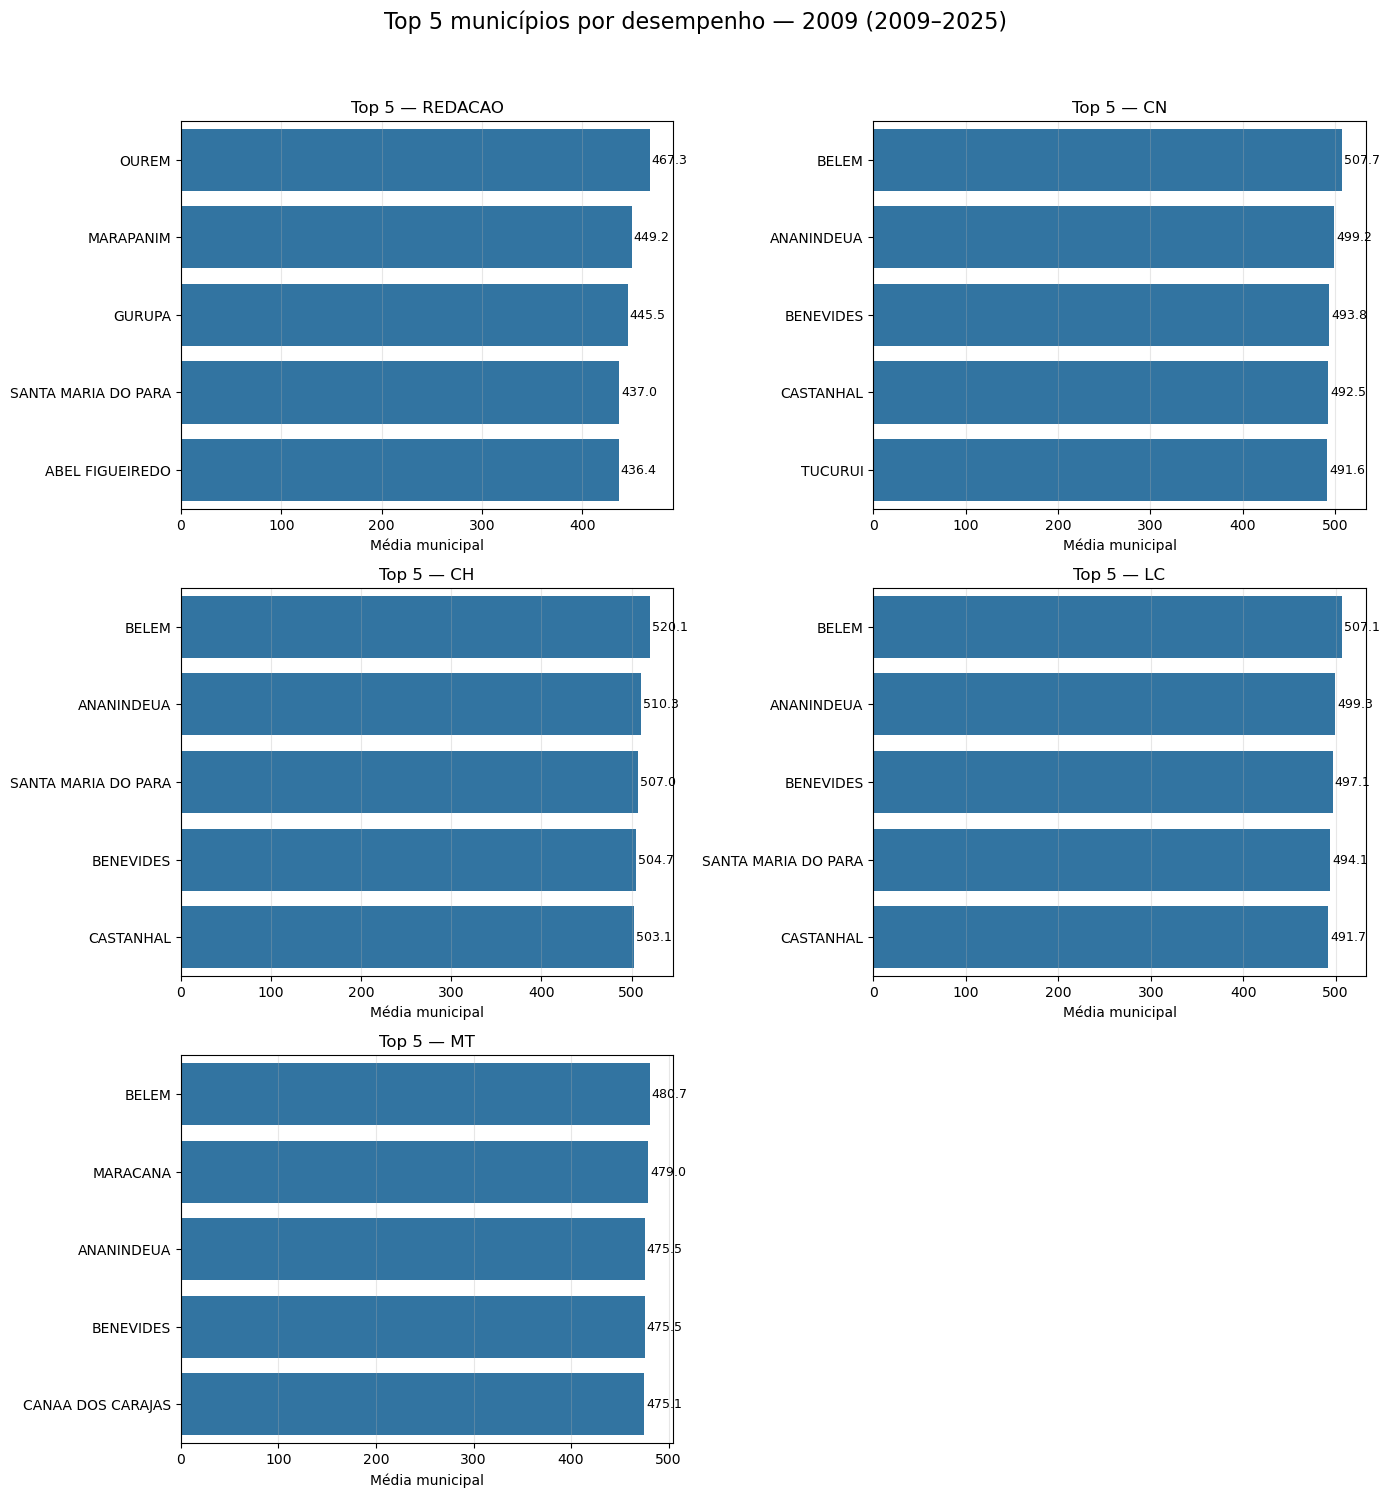

In [49]:
# ============================================================
# 6.1. GRÁFICO — TOP 5 POR DESEMPENHO
# ============================================================
n, ncols = len(colunas_top5), 2
nrows = int(np.ceil(n / ncols))
fig, axes = plt.subplots(nrows, ncols, figsize=(14, 5 * nrows))
axes = np.atleast_1d(axes).flatten()
for i, (coluna, disciplina) in enumerate(colunas_top5.items()):
    ax = axes[i]
    dados = (dados_ano[["NO_MUNICIPIO_TERRITORIO", coluna]].dropna()
             .sort_values(coluna, ascending=False).head(5).sort_values(coluna,ascending=False))
    sns.barplot(data=dados, x=coluna, y="NO_MUNICIPIO_TERRITORIO", ax=ax, orient="h")
    for barra in ax.patches:
        valor = barra.get_width()
        if pd.notna(valor):
            ax.text(valor + 2, barra.get_y()+barra.get_height()/2, f"{valor:.1f}",
                    va="center", fontsize=9)
    ax.set_title(f"Top 5 — {disciplina}")
    ax.set_xlabel("Média municipal")
    ax.set_ylabel("")
    ax.grid(axis="x", alpha=.3)
for j in range(n, len(axes)):
    axes[j].set_visible(False)
fig.suptitle(f"Top 5 municípios por desempenho — {ANO_TRANSVERSAL} ({PERIODO_TRANSVERSAL['rotulo']})",
             fontsize=16, y=.995)
plt.tight_layout(rect=[0, 0, 1, .97])
plt.show()


## 7. Outros indicadores para Top 5

In [8]:
# ============================================================
# 7. OUTROS INDICADORES — TOP 5
# ============================================================
colunas_indicadores = [
    "NO_MUNICIPIO_TERRITORIO", "n_participantes", *colunas_medias,
    "pct_escola_privada", "pct_escola_federal", "pct_escola_estadual",
    "pct_escola_municipal", "n_dependencia_informada"
]
indicadores_top5 = dados_ano[[c for c in colunas_indicadores if c in dados_ano.columns]].copy()

# Média simples das cinco disciplinas somente em 2009–2025.
# OBJETIVA não é combinada com as quatro áreas posteriores.
top5_media_5_areas = pd.DataFrame()
if PERIODO_ID_TRANSVERSAL == "2009_2025":
    colunas_areas = ["media_redacao", "media_cn", "media_ch", "media_lc", "media_mt"]
    if all(c in indicadores_top5.columns for c in colunas_areas):
        indicadores_top5["media_5_areas"] = indicadores_top5[colunas_areas].mean(axis=1, skipna=False)
        top5_media_5_areas = (indicadores_top5[
            ["NO_MUNICIPIO_TERRITORIO", "media_5_areas", "n_participantes"]
        ].dropna(subset=["media_5_areas"]).sort_values("media_5_areas", ascending=False)
          .head(5).reset_index(drop=True))
        print("TOP 5 — MÉDIA SIMPLES DAS CINCO DISCIPLINAS (indicador descritivo)")
        display(top5_media_5_areas.round(2))
else:
    print("Média simples das cinco áreas não calculada: 1998–2008 utiliza OBJETIVA.")

colunas_pct = ["pct_escola_federal", "pct_escola_estadual", "pct_escola_municipal"]
if all(c in indicadores_top5.columns for c in colunas_pct):
    indicadores_top5["pct_escola_publica"] = indicadores_top5[colunas_pct].sum(axis=1, min_count=3)
    for coluna, rotulo in [
        ("pct_escola_privada", "TOP 5 — PROPORÇÃO DE ESCOLA PRIVADA"),
        ("pct_escola_publica", "TOP 5 — PROPORÇÃO DE ESCOLA PÚBLICA")
    ]:
        if coluna in indicadores_top5.columns:
            print(rotulo)
            display(indicadores_top5[["NO_MUNICIPIO_TERRITORIO", coluna, "n_participantes"]]
                    .dropna(subset=[coluna]).sort_values(coluna, ascending=False)
                    .head(5).reset_index(drop=True).round(2))


TOP 5 — MÉDIA SIMPLES DAS CINCO DISCIPLINAS (indicador descritivo)


,NO_MUNICIPIO_TERRITORIO,media_5_areas,n_participantes
0,SANTA MARIA DO PARA,478.92,92
1,BELEM,477.91,39456
2,ANANINDEUA,473.28,9996
3,BARCARENA,471.96,1717
4,CASTANHAL,469.93,3293


TOP 5 — PROPORÇÃO DE ESCOLA PRIVADA


,NO_MUNICIPIO_TERRITORIO,pct_escola_privada,n_participantes
0,CONCEICAO DO ARAGUAIA,18.27,542
1,SAO FELIX DO XINGU,17.48,103
2,PARAGOMINAS,14.33,1270
3,TUCUMA,13.83,347
4,CANAA DOS CARAJAS,10.86,267


TOP 5 — PROPORÇÃO DE ESCOLA PÚBLICA


,NO_MUNICIPIO_TERRITORIO,pct_escola_publica,n_participantes
0,SAO CAETANO DE ODIVELAS,73.42,79
1,OBIDOS,69.35,509
2,CONCORDIA DO PARA,65.78,263
3,GURUPA,63.64,11
4,PONTA DE PEDRAS,62.75,102


## 9. Relação entre disciplinas válidas no período

In [9]:
# ============================================================
# 9. RELAÇÃO ENTRE DISCIPLINAS DISPONÍVEIS NO PERÍODO
# ============================================================
colunas_correlacao = list(colunas_top5.keys())
correlacao = dados_ano[colunas_correlacao].corr()
display(correlacao.round(3))


,media_redacao,media_cn,media_ch,media_lc,media_mt
media_redacao,1.000,0.158,0.251,0.228,0.046
media_cn,0.158,1.000,0.880,0.917,0.732
media_ch,0.251,0.880,1.000,0.919,0.759
media_lc,0.228,0.917,0.919,1.000,0.794
media_mt,0.046,0.732,0.759,0.794,1.000


### 9.1 Matriz de correlação das disciplinas válidas

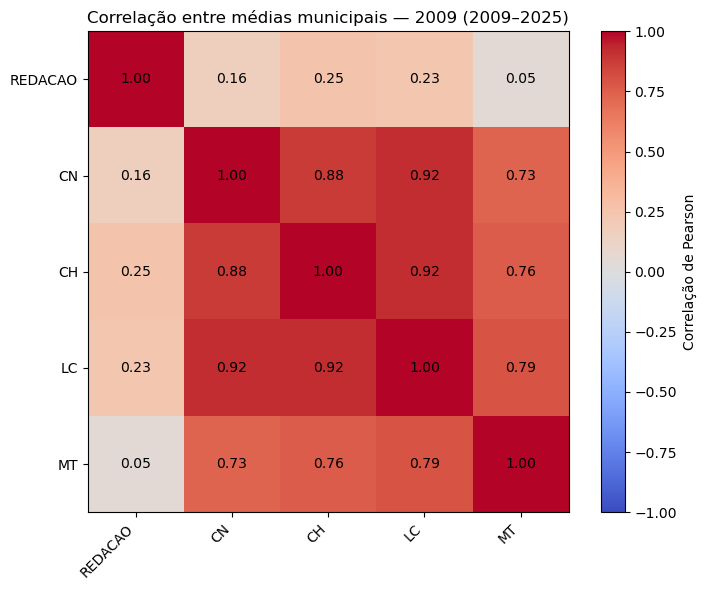

In [10]:
# ============================================================
# 9.1 MATRIZ DE CORRELAÇÃO
# ============================================================
rotulos_correlacao = [nomes_disciplinas[c] for c in colunas_correlacao]
fig, ax = plt.subplots(figsize=(max(6, 1.5*len(colunas_correlacao)),
                               max(5, 1.2*len(colunas_correlacao))))
im = ax.imshow(correlacao, vmin=-1, vmax=1, cmap="coolwarm")
ax.set_xticks(range(len(colunas_correlacao)))
ax.set_yticks(range(len(colunas_correlacao)))
ax.set_xticklabels(rotulos_correlacao, rotation=45, ha="right")
ax.set_yticklabels(rotulos_correlacao)
for i in range(len(colunas_correlacao)):
    for j in range(len(colunas_correlacao)):
        valor = correlacao.iloc[i, j]
        ax.text(j, i, f"{valor:.2f}" if pd.notna(valor) else "NA", ha="center", va="center")
ax.set_title(f"Correlação entre médias municipais — {ANO_TRANSVERSAL} ({PERIODO_TRANSVERSAL['rotulo']})")
fig.colorbar(im, ax=ax, label="Correlação de Pearson")
plt.tight_layout()
plt.show()


## 10. Escola × desempenho

In [11]:
# ============================================================
# 10. ESCOLA × DESEMPENHO
# ============================================================

if not TEM_GRUPOS_ANO:

    escola_ano = pd.DataFrame()

    print(f"Sem dados de ESCOLA para {ANO_TRANSVERSAL} "
        "no produto desempenho_grupos_municipal.")

else:

    escola_ano = (grupo[(grupo["ano"] == ANO_TRANSVERSAL) &
                  (grupo["tipo_grupo"].str.upper().eq("ESCOLA")) &
                  (grupo["disciplina"].isin(ORDEM_DISCIPLINAS))]
        .copy()
        [["NO_MUNICIPIO_TERRITORIO",
                "grupo",
                "disciplina",
                "n_validos",
                "media",
                "mediana",
                "std"]]
        .sort_values(["disciplina","grupo","NO_MUNICIPIO_TERRITORIO"])
        .reset_index(drop=True))
    display(escola_ano)


,NO_MUNICIPIO_TERRITORIO,grupo,disciplina,n_validos,media,mediana,std
0,ABAETETUBA,ESTADUAL,CH,716,460.938827,448.35,82.364715
1,ABEL FIGUEIREDO,ESTADUAL,CH,49,446.587755,423.60,76.038084
2,ACARA,ESTADUAL,CH,87,429.144828,413.70,65.980612
3,ALENQUER,ESTADUAL,CH,180,440.367778,432.75,71.864452
4,ALMEIRIM,ESTADUAL,CH,73,456.127397,434.50,75.318201
...,...,...,...,...,...,...,...
1380,TUCUMA,PRIVADA,REDACAO,48,397.395833,500.00,279.400935
1381,TUCURUI,PRIVADA,REDACAO,72,499.652778,575.00,268.160566
1382,URUARA,PRIVADA,REDACAO,25,294.000000,0.00,322.771204
1383,VIGIA,PRIVADA,REDACAO,1,700.000000,700.00,NaN


## 10.1 Síntese estadual — Escola × desempenho

In [12]:
# ============================================================
# 10.1. SÍNTESE ESTADUAL — ESCOLA × DESEMPENHO
# ============================================================

def media_ponderada_grupo(df):

    peso = df["n_validos"]

    validos = (df["media"].notna()
               & peso.notna()
               & (peso > 0))
    
    if not validos.any():
        return np.nan

    return ((
            df.loc[validos, "media"]
            * peso.loc[validos]
        ).sum()
        / peso.loc[validos].sum())
    
if escola_ano.empty:
    escola_resumo = pd.DataFrame()
else:
    escola_resumo = (
        escola_ano
        .groupby(
            ["grupo", "disciplina"],
            dropna=False
        ).apply(
            lambda g: pd.Series({
                "n_validos": g["n_validos"].sum(),
                "media": media_ponderada_grupo(g),
                "mediana_municipal": g["mediana"].median(),
                "std_municipal": g["std"].median(),
                "n_municipios":
                    g["NO_MUNICIPIO_TERRITORIO"].nunique()}),
            include_groups=False)
        .reset_index().sort_values(["disciplina", "grupo"])
        .reset_index(drop=True)
    )
display(escola_resumo.round(2))


,grupo,disciplina,n_validos,media,mediana_municipal,std_municipal,n_municipios
0,ESTADUAL,CH,22927.0,463.15,442.52,74.68,76.0
1,FEDERAL,CH,588.0,592.11,583.15,77.98,16.0
2,MUNICIPAL,CH,721.0,449.23,432.55,69.02,53.0
3,NAO_INFORMADA,CH,44955.0,505.28,477.18,85.57,76.0
4,PRIVADA,CH,5027.0,555.38,526.10,84.55,54.0
5,ESTADUAL,CN,22927.0,456.54,446.70,73.44,76.0
6,FEDERAL,CN,588.0,589.00,593.65,82.96,16.0
7,MUNICIPAL,CN,721.0,447.41,448.55,72.83,53.0
8,NAO_INFORMADA,CN,44955.0,494.74,475.30,77.56,76.0
9,PRIVADA,CN,5027.0,550.63,536.15,88.37,54.0


### 10.2 Visualização — Escola × desempenho

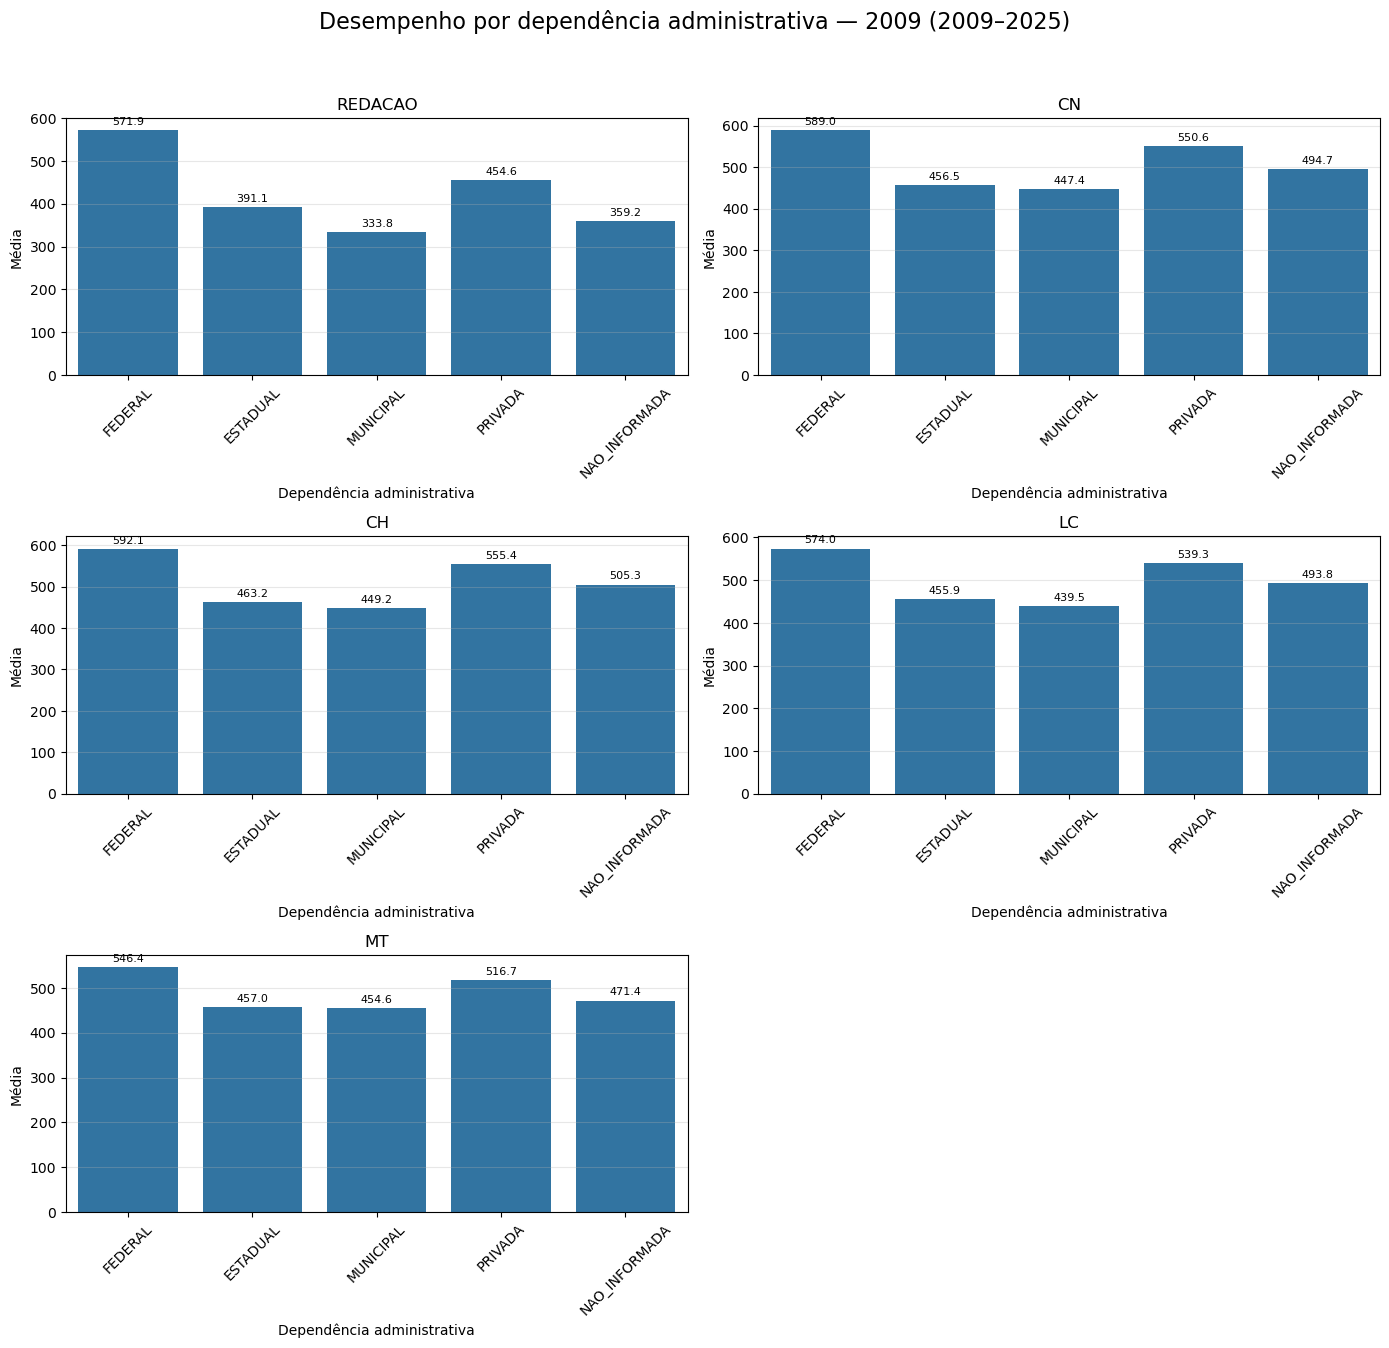

In [13]:
# ============================================================
# 10.2. VISUALIZAÇÃO — ESCOLA × DESEMPENHO
# ============================================================
if escola_resumo.empty:
    print(f"Visualização indisponível para {ANO_TRANSVERSAL}: não há dados de desempenho por escola.")
else:
    ordem_escola = ["FEDERAL", "ESTADUAL", "MUNICIPAL", "PRIVADA", "NAO_INFORMADA"]
    ordem_disciplinas = [d for d in ORDEM_DISCIPLINAS if d in escola_resumo["disciplina"].unique()]
    n, ncols = len(ordem_disciplinas), 2
    nrows = int(np.ceil(n / ncols))
    fig, axes = plt.subplots(nrows, ncols, figsize=(14, 4.5*nrows))
    axes = np.atleast_1d(axes).flatten()
    for i, disciplina in enumerate(ordem_disciplinas):
        dados = escola_resumo[escola_resumo["disciplina"] == disciplina]
        ax = sns.barplot(data=dados, x="grupo", y="media", order=ordem_escola, ax=axes[i])
        for barra in ax.patches:
            valor = barra.get_height()
            if pd.notna(valor):
                ax.text(barra.get_x()+barra.get_width()/2, valor+8, f"{valor:.1f}",
                        ha="center", va="bottom", fontsize=8)
        ax.set_title(disciplina)
        ax.set_xlabel("Dependência administrativa")
        ax.set_ylabel("Média")
        ax.tick_params(axis="x", rotation=45)
        ax.grid(axis="y", alpha=.3)
    for j in range(n, len(axes)):
        axes[j].set_visible(False)
    fig.suptitle(f"Desempenho por dependência administrativa — {ANO_TRANSVERSAL} ({PERIODO_TRANSVERSAL['rotulo']})",
                 fontsize=16, y=.995)
    plt.tight_layout(rect=[0, 0, 1, .97])
    plt.show()


## 11. Sexo × desempenho

In [14]:
# ============================================================
# 11. SEXO × DESEMPENHO
# ============================================================

if not TEM_GRUPOS_ANO:

    sexo_ano = pd.DataFrame()

    print(f"Sem dados de SEXO para {ANO_TRANSVERSAL} "
        "no produto desempenho_grupos_municipal.")


else:
    sexo_ano = (grupo[(grupo["ano"] == ANO_TRANSVERSAL) &
                  (grupo["tipo_grupo"].str.upper().eq("SEXO")) &
                  (grupo["disciplina"].isin(ORDEM_DISCIPLINAS))].copy()
                [["NO_MUNICIPIO_TERRITORIO",
                  "grupo",
                  "disciplina",
                  "n_validos",
                  "media",
                  "mediana",
                  "std"]]
                .sort_values(["disciplina","grupo","NO_MUNICIPIO_TERRITORIO"])
                .reset_index(drop=True))
display(sexo_ano)

,NO_MUNICIPIO_TERRITORIO,grupo,disciplina,n_validos,media,mediana,std
0,ABAETETUBA,FEMININO,CH,1403,477.403849,465.2,87.069930
1,ABEL FIGUEIREDO,FEMININO,CH,69,454.682609,434.5,74.695054
2,ACARA,FEMININO,CH,119,443.462185,433.4,72.361283
3,ALENQUER,FEMININO,CH,171,439.145029,428.3,74.804940
4,ALMEIRIM,FEMININO,CH,79,455.970886,449.9,69.164783
...,...,...,...,...,...,...,...
755,TUCUMA,MASCULINO,REDACAO,131,324.809160,425.0,275.672189
756,TUCURUI,MASCULINO,REDACAO,866,350.981524,475.0,292.372527
757,URUARA,MASCULINO,REDACAO,109,337.844037,475.0,286.292041
758,VIGIA,MASCULINO,REDACAO,219,362.899543,425.0,312.124518


### 11.1 Síntese estadual — Sexo × desempenho

In [15]:
# ============================================================
# 11.1. SÍNTESE ESTADUAL — SEXO × DESEMPENHO
# ============================================================

if sexo_ano.empty:

    sexo_resumo = pd.DataFrame()

    print(f"Síntese indisponível para {ANO_TRANSVERSAL}.")

else:

    sexo_resumo = (
        sexo_ano
        .groupby(
            ["grupo", "disciplina"],
            dropna=False
        )
        .apply(
            lambda g: pd.Series({
                "n_validos": g["n_validos"].sum(),
                "media": media_ponderada_grupo(g),
                "mediana_municipal": g["mediana"].median(),
                "std_municipal": g["std"].median(),
                "n_municipios":
                    g["NO_MUNICIPIO_TERRITORIO"].nunique(),
            }),
            include_groups=False
        )
        .reset_index()
        .sort_values(
            ["disciplina", "grupo"]
        )
        .reset_index(drop=True)
    )

    display(
        sexo_resumo.round(2)
    )


,grupo,disciplina,n_validos,media,mediana_municipal,std_municipal,n_municipios
0,FEMININO,CH,46940.0,486.07,453.35,77.54,76.0
1,MASCULINO,CH,27278.0,512.55,472.00,89.30,76.0
2,FEMININO,CN,46940.0,475.13,451.62,73.86,76.0
3,MASCULINO,CN,27278.0,507.47,481.00,82.57,76.0
4,FEMININO,LC,45081.0,484.05,454.95,82.85,76.0
5,MASCULINO,LC,25796.0,487.00,459.38,89.05,76.0
6,FEMININO,MT,45081.0,461.84,449.35,64.04,76.0
7,MASCULINO,MT,25796.0,485.41,464.05,73.82,76.0
8,FEMININO,REDACAO,68230.0,388.91,500.00,299.38,76.0
9,MASCULINO,REDACAO,41141.0,352.07,431.25,290.92,76.0


### 11.2 Visualização — Sexo × desempenho

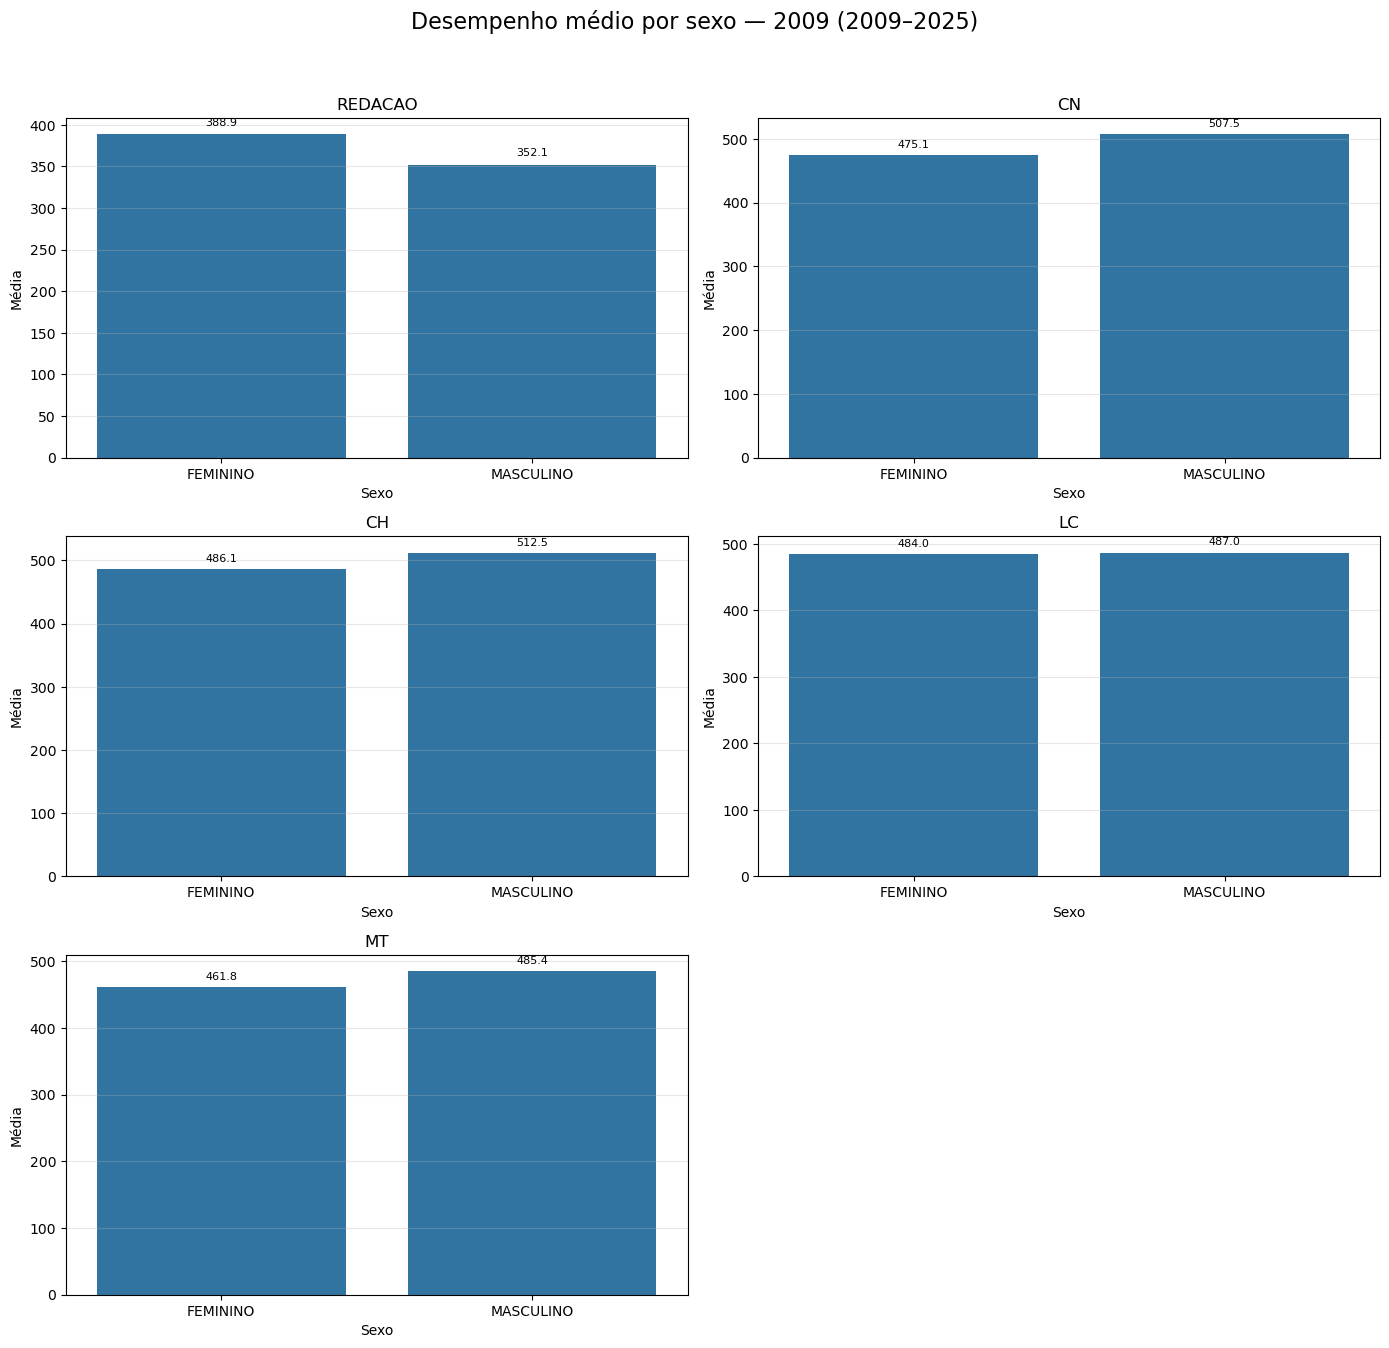

In [16]:
# ============================================================
# 11.2. VISUALIZAÇÃO — SEXO × DESEMPENHO
# ============================================================
if sexo_resumo.empty:
    print(f"Visualização indisponível para {ANO_TRANSVERSAL}.")
else:
    ordem_disciplinas = [d for d in ORDEM_DISCIPLINAS if d in sexo_resumo["disciplina"].unique()]
    n, ncols = len(ordem_disciplinas), 2
    nrows = int(np.ceil(n / ncols))
    fig, axes = plt.subplots(nrows, ncols, figsize=(14, 4.5*nrows))
    axes = np.atleast_1d(axes).flatten()
    for i, disciplina in enumerate(ordem_disciplinas):
        dados = sexo_resumo[sexo_resumo["disciplina"] == disciplina]
        ax = sns.barplot(data=dados, x="grupo", y="media", ax=axes[i])
        for barra in ax.patches:
            valor = barra.get_height()
            if pd.notna(valor):
                ax.text(barra.get_x()+barra.get_width()/2, valor+8, f"{valor:.1f}",
                        ha="center", va="bottom", fontsize=8)
        ax.set_title(disciplina)
        ax.set_xlabel("Sexo")
        ax.set_ylabel("Média")
        ax.grid(axis="y", alpha=.3)
    for j in range(n, len(axes)):
        axes[j].set_visible(False)
    fig.suptitle(f"Desempenho médio por sexo — {ANO_TRANSVERSAL} ({PERIODO_TRANSVERSAL['rotulo']})",
                 fontsize=16, y=.995)
    plt.tight_layout(rect=[0, 0, 1, .97])
    plt.show()


## 12. Faixa etária × desempenho

### 12.1 Proporção dos participantes por faixa etária

Antes de comparar desempenho, calculamos a composição dos participantes nas cinco faixas etárias analíticas definidas para o projeto.

In [17]:

faixa_ano = (faixa[faixa["ano"] == ANO_TRANSVERSAL].copy())

faixa_ano["grupo_faixa"] = (pd.to_numeric(
    faixa_ano["TP_FAIXA_ETARIA"],errors="coerce").map(MAPA_FAIXA_5))

proporcao_faixa = (faixa_ano[faixa_ano["grupo_faixa"].notna()]
    .groupby("grupo_faixa",as_index=False)["n_participantes"].sum())

proporcao_faixa["pct_participantes"] = (proporcao_faixa["n_participantes"]
    / proporcao_faixa["n_participantes"].sum()* 100)

proporcao_faixa["grupo_faixa"] = pd.Categorical(
    proporcao_faixa["grupo_faixa"],categories=ORDEM_FAIXAS,
    ordered=True)

proporcao_faixa = (proporcao_faixa.sort_values("grupo_faixa")
    .reset_index(drop=True))

print(f"Distribuição etária dos participantes — "
      f"{ANO_TRANSVERSAL}")

display(proporcao_faixa.round(2))

print(f"\nTotal considerado: "
      f"{proporcao_faixa['n_participantes'].sum():,.0f}")

print(f"Soma dos percentuais: "
      f"{proporcao_faixa['pct_participantes'].sum():.2f}%")


Distribuição etária dos participantes — 2009


,grupo_faixa,n_participantes,pct_participantes
0,<17,630,0.58
1,17–20,38174,34.90
2,21–25,35761,32.70
3,26–40,29608,27.07
4,>40,5198,4.75



Total considerado: 109,371
Soma dos percentuais: 100.00%


In [18]:
if not TEM_GRUPOS_ANO:

    faixa_desempenho = pd.DataFrame()
    print(f"Sem dados de FAIXA_ETARIA para {ANO_TRANSVERSAL} "
          "no produto desempenho_grupos_municipal.")
else:

    faixa_desempenho = (grupo[ (grupo["ano"] == ANO_TRANSVERSAL) &
            (grupo["tipo_grupo"].str.upper().eq("FAIXA_ETARIA")) &
            (grupo["disciplina"].isin(ORDEM_DISCIPLINAS))].copy())

    faixa_desempenho["grupo_faixa"] = (
        pd.to_numeric(faixa_desempenho["grupo"],errors="coerce")
        .map(MAPA_FAIXA_5)
    )

    faixa_desempenho = (
        faixa_desempenho[
            faixa_desempenho["grupo_faixa"].notna()])

    faixa_desempenho = (
        faixa_desempenho
        .groupby([
                "NO_MUNICIPIO_TERRITORIO",
                "grupo_faixa",
                "disciplina"],
            dropna=False)
        .apply(
            lambda g: pd.Series({
                "n_validos": g["n_validos"].sum(),
                "media": media_ponderada_grupo(g),
            }),
            include_groups=False
        ).reset_index().sort_values([
                "disciplina",
                "grupo_faixa",
                "NO_MUNICIPIO_TERRITORIO"])
        .reset_index(drop=True))
display(faixa_desempenho.round(2))


,NO_MUNICIPIO_TERRITORIO,grupo_faixa,disciplina,n_validos,media
0,ABAETETUBA,17–20,CH,924.0,491.86
1,ABEL FIGUEIREDO,17–20,CH,50.0,450.39
2,ACARA,17–20,CH,64.0,453.70
3,ALENQUER,17–20,CH,139.0,459.30
4,ALMEIRIM,17–20,CH,56.0,472.14
...,...,...,...,...,...
1776,TUCUMA,>40,REDACAO,10.0,310.00
1777,TUCURUI,>40,REDACAO,91.0,272.53
1778,URUARA,>40,REDACAO,4.0,287.50
1779,VIGIA,>40,REDACAO,20.0,281.25


### 12.2 Síntese estadual — Faixa etária × desempenho

In [19]:
# ============================================================
# 12.1. SÍNTESE ESTADUAL — FAIXA ETÁRIA × DESEMPENHO
# ============================================================

if faixa_desempenho.empty:

    faixa_resumo = pd.DataFrame()

    print(f"Síntese indisponível para {ANO_TRANSVERSAL}.")

else:

    faixa_resumo = (
        faixa_desempenho
        .groupby(
            ["grupo_faixa", "disciplina"],
            dropna=False)
        .apply(
            lambda g: pd.Series({
                "n_validos": g["n_validos"].sum(),
                "media": media_ponderada_grupo(g),
                "mediana_municipal": g["media"].median(),
                "n_municipios":
                    g["NO_MUNICIPIO_TERRITORIO"].nunique(),
            }),
            include_groups=False
        ).reset_index())

    faixa_resumo["grupo_faixa"] = pd.Categorical(faixa_resumo["grupo_faixa"],categories=ORDEM_FAIXAS,ordered=True)
    faixa_resumo = (faixa_resumo.sort_values(["disciplina", "grupo_faixa"]).reset_index(drop=True))

    display(faixa_resumo.round(2))


,grupo_faixa,disciplina,n_validos,media,mediana_municipal,n_municipios
0,<17,CH,453.0,486.80,478.22,56.0
1,17–20,CH,30570.0,502.30,471.29,76.0
2,21–25,CH,23397.0,490.14,465.02,76.0
3,26–40,CH,16775.0,494.68,472.08,76.0
4,>40,CH,3023.0,481.43,464.78,72.0
5,<17,CN,453.0,489.24,482.30,56.0
6,17–20,CN,30570.0,496.07,470.13,76.0
7,21–25,CN,23397.0,482.53,462.78,76.0
8,26–40,CN,16775.0,480.96,466.81,76.0
9,>40,CN,3023.0,463.48,453.36,72.0


### 12.3 Perfil etário do desempenho

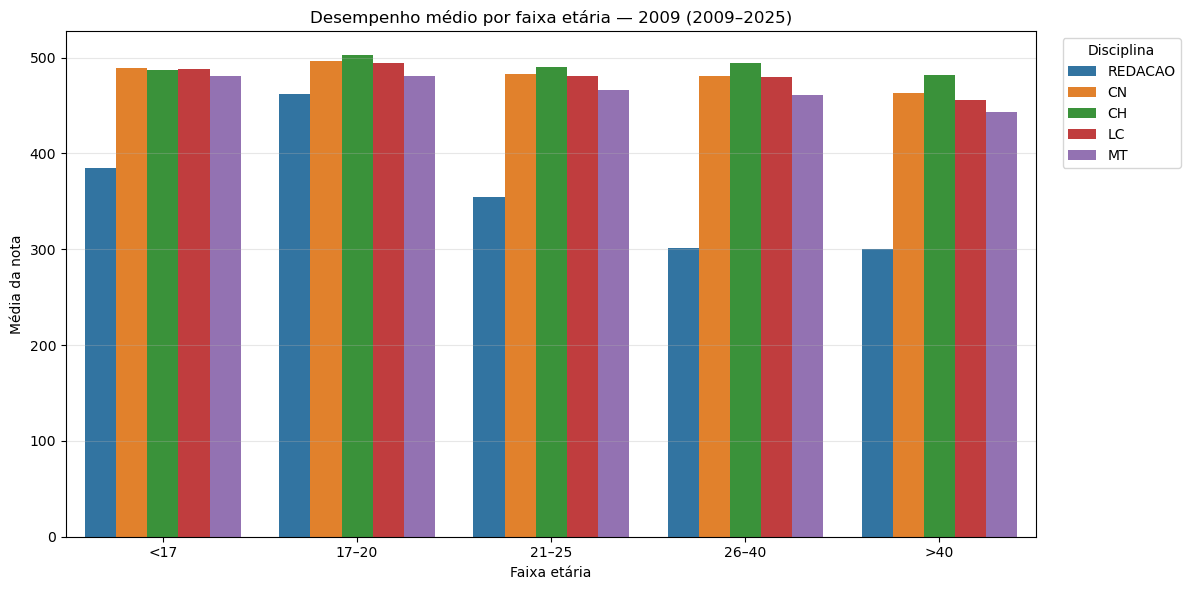

In [20]:
# ============================================================
# 12.2. PERFIL ETÁRIO DO DESEMPENHO
# ============================================================
if faixa_resumo.empty:
    print(f"Visualização indisponível para {ANO_TRANSVERSAL}.")
else:
    ordem_disciplinas = [d for d in ORDEM_DISCIPLINAS if d in faixa_resumo["disciplina"].unique()]
    fig, ax = plt.subplots(figsize=(12, 6))
    sns.barplot(data=faixa_resumo, x="grupo_faixa", y="media",
                hue="disciplina", order=ORDEM_FAIXAS,
                hue_order=ordem_disciplinas, ax=ax)
    ax.set_xlabel("Faixa etária")
    ax.set_ylabel("Média da nota")
    ax.set_title(f"Desempenho médio por faixa etária — {ANO_TRANSVERSAL} ({PERIODO_TRANSVERSAL['rotulo']})")
    ax.legend(title="Disciplina", bbox_to_anchor=(1.02, 1), loc="upper left")
    ax.grid(axis="y", alpha=.3)
    plt.tight_layout()
    plt.show()


### 12.4 Distribuição etária dos participantes

In [21]:
# ============================================================
# 12.3. DISTRIBUIÇÃO ETÁRIA DOS PARTICIPANTES
# ============================================================

faixa_ano = faixa[faixa["ano"] == ANO_TRANSVERSAL].copy()

if faixa_ano.empty:

    print(f"Sem dados de faixa etária para {ANO_TRANSVERSAL}.")

else:

    faixa_ano["grupo_faixa"] = (
        pd.to_numeric(
            faixa_ano["TP_FAIXA_ETARIA"],
            errors="coerce"
        )
        .map(MAPA_FAIXA_5)
    )

    perfil_etario_participacao = (
        faixa_ano[
            faixa_ano["grupo_faixa"].notna()
        ]
        .groupby(
            "grupo_faixa"
        )["n_participantes"]
        .sum()
        .reindex(ORDEM_FAIXAS)
        .rename("n_participantes")
        .reset_index()
    )

    perfil_etario_participacao["pct"] = (
        perfil_etario_participacao["n_participantes"]
        / perfil_etario_participacao["n_participantes"].sum()* 100
    )

    display(perfil_etario_participacao.round(2))

,grupo_faixa,n_participantes,pct
0,<17,630,0.58
1,17–20,38174,34.90
2,21–25,35761,32.70
3,26–40,29608,27.07
4,>40,5198,4.75


## 13. Perfil municipal do ano transversal

In [22]:
# ============================================================
# 13. PERFIL MUNICIPAL DO ANO TRANSVERSAL
# ============================================================
colunas_perfil = [
    "CO_MUNICIPIO_TERRITORIO", "NO_MUNICIPIO_TERRITORIO",
    "n_participantes", *colunas_medias
]
colunas_perfil = [c for c in colunas_perfil if c in dados_ano.columns]
perfil_municipal = (dados_ano[colunas_perfil]
                    .sort_values("n_participantes", ascending=False)
                    .reset_index(drop=True))
display(perfil_municipal.round(2))


,CO_MUNICIPIO_TERRITORIO,NO_MUNICIPIO_TERRITORIO,n_participantes,media_redacao,media_cn,media_ch,media_lc,media_mt
0,1501402,BELEM,39456,374.02,507.68,520.07,507.06,480.69
1,1506807,SANTAREM,10166,413.27,471.28,479.60,471.30,464.56
2,1500800,ANANINDEUA,9996,382.08,499.18,510.28,499.31,475.52
3,1504208,MARABA,3414,373.65,481.80,485.30,478.91,468.73
4,1502400,CASTANHAL,3293,388.53,492.51,503.08,491.74,473.82
...,...,...,...,...,...,...,...,...
71,1505700,PONTA DE PEDRAS,102,349.51,457.84,466.89,447.83,448.22
72,1506609,SANTA MARIA DO PARA,92,436.96,489.42,506.97,494.13,467.11
73,1504901,MUANA,86,420.64,430.05,465.38,445.45,458.71
74,1507102,SAO CAETANO DE ODIVELAS,79,395.25,443.09,453.23,455.98,450.53


### 13.1 Participação × desempenho

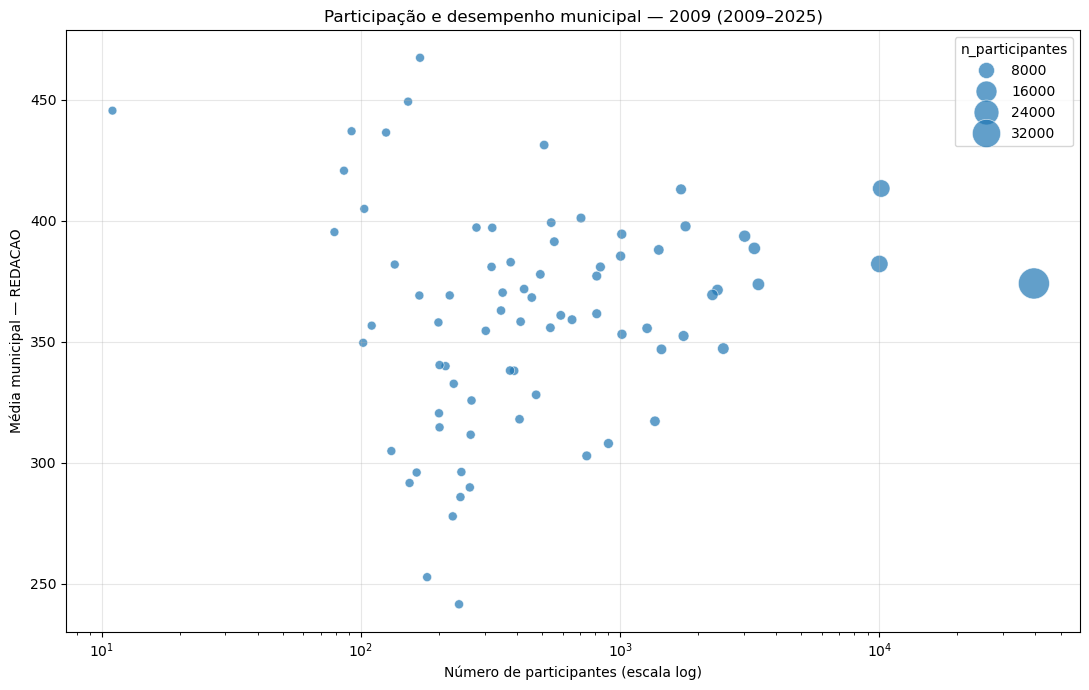

Variável complementar disponível: CN


In [23]:
# ============================================================
# 13.1. PARTICIPAÇÃO × DESEMPENHO
# ============================================================
# Usa a Redação do período e a primeira disciplina não-Redação disponível.
coluna_redacao = "media_redacao"
colunas_alternativas = [c for c in colunas_medias if c != coluna_redacao]
coluna_comparacao = colunas_alternativas[0] if colunas_alternativas else None

if coluna_redacao not in dados_ano.columns or coluna_comparacao is None:
    print("Gráfico participação × desempenho indisponível para esta estrutura.")
else:
    dados_participacao = dados_ano[
        ["NO_MUNICIPIO_TERRITORIO", "n_participantes", coluna_redacao, coluna_comparacao]
    ].dropna().copy()
    fig, ax = plt.subplots(figsize=(11, 7))
    sns.scatterplot(data=dados_participacao, x="n_participantes", y=coluna_redacao,
                    size="n_participantes", sizes=(40, 500), alpha=.7, ax=ax)
    ax.set_xscale("log")
    ax.set_xlabel("Número de participantes (escala log)")
    ax.set_ylabel(f"Média municipal — {nomes_disciplinas[coluna_redacao]}")
    ax.set_title(f"Participação e desempenho municipal — {ANO_TRANSVERSAL} ({PERIODO_TRANSVERSAL['rotulo']})")
    ax.grid(axis="both", alpha=.3)
    plt.tight_layout()
    plt.show()
    print(f"Variável complementar disponível: {nomes_disciplinas[coluna_comparacao]}")


## 14. Síntese transversal

In [45]:
# ============================================================
# 14. SÍNTESE TRANSVERSAL
# ============================================================
print("=" * 80)
print(f"SÍNTESE — {ANO_TRANSVERSAL}")
print(f"Período metodológico: {PERIODO_TRANSVERSAL['rotulo']}")
print(f"Estrutura: {PERIODO_TRANSVERSAL['estrutura']}")
print("=" * 80)
print(f"Municípios com registros: {dados_ano['CO_MUNICIPIO_TERRITORIO'].nunique():,}")
print(f"Participantes: {dados_ano['n_participantes'].sum():,.0f}")

dados_maior = dados_ano[colunas_medias].copy()
dados_maior["disciplina"] = dados_maior.idxmax(axis=1).map(nomes_disciplinas)
print("\nDisciplina com maior média municipal:")
display(dados_maior["disciplina"].value_counts().rename("n_municipios").to_frame())

dados_menor = dados_ano[colunas_medias].copy()
dados_menor["disciplina"] = dados_menor.idxmin(axis=1).map(nomes_disciplinas)
print("\nDisciplina com menor média municipal:")
display(dados_menor["disciplina"].value_counts().rename("n_municipios").to_frame())

if PERIODO_ID_TRANSVERSAL == "2009_2025" and not top5_media_5_areas.empty:
    print("\nTop 5 — média simples das cinco disciplinas:")
    display(top5_media_5_areas.round(2))
if not TEM_GRUPOS_ANO:
    print(f"\nDesempenho por escola, sexo e faixa etária indisponível para {ANO_TRANSVERSAL}.")


print("\n>> Processo finalizado em:", time.strftime("%d/%m/%Y - %H:%M:%S"))

SÍNTESE — 2009
Período metodológico: 2009–2025
Estrutura: AREAS
Municípios com registros: 76
Participantes: 109,371

Disciplina com maior média municipal:


,n_municipios
disciplina,
CH,52
CN,17
MT,5
LC,2



Disciplina com menor média municipal:


,n_municipios
disciplina,
REDACAO,73
MT,2
CN,1



Top 5 — média simples das cinco disciplinas:


,NO_MUNICIPIO_TERRITORIO,media_5_areas,n_participantes
0,SANTA MARIA DO PARA,478.92,92
1,BELEM,477.91,39456
2,ANANINDEUA,473.28,9996
3,BARCARENA,471.96,1717
4,CASTANHAL,469.93,3293



>> Processo finalizado em: 03/11/2026 - 14:19:33
